In [2]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
import re

base = "https://books.toscrape.com/catalogue/page-{}.html"
all_books = []

for page in range(1, 51):
    url = base.format(page)
    res = requests.get(url)
    soup = BeautifulSoup(res.text, "html.parser")
    for book in soup.select("article.product_pod"):
        title = book.h3.a["title"]
        price = float(re.sub(r"[^0-9.]", "", book.select_one("p.price_color").text))
        rating_word = book.select_one("p.star-rating")["class"][1]
        rating_map = {"One":1,"Two":2,"Three":3,"Four":4,"Five":5}
        avail_text = book.select_one("p.instock.availability").text.strip()
        availability = "In stock" if "In stock" in avail_text else "Out of stock"
        link = "https://books.toscrape.com/catalogue/" + book.h3.a["href"]
        d = BeautifulSoup(requests.get(link).text, "html.parser")
        category = d.select("ul.breadcrumb li a")[2].text.strip()
        qty_match = re.search(r"\((\d+) available\)", d.select_one("p.instock.availability").text)
        qty = int(qty_match.group(1)) if qty_match else 0
        all_books.append([title, price, rating_word, rating_map[rating_word], availability, qty, category])
    print(f"Done page {page}/50 - total {len(all_books)}")

df = pd.DataFrame(all_books, columns=["title","price_gbp","rating_word","rating","availability","quantity_in_stock","category"])
print(df.shape)
print(df.head())
df.to_csv("books_scraped_dataset.csv", index=False)

Done page 1/50 - total 20
Done page 2/50 - total 40
Done page 3/50 - total 60
Done page 4/50 - total 80
Done page 5/50 - total 100
Done page 6/50 - total 120
Done page 7/50 - total 140
Done page 8/50 - total 160
Done page 9/50 - total 180
Done page 10/50 - total 200
Done page 11/50 - total 220
Done page 12/50 - total 240
Done page 13/50 - total 260
Done page 14/50 - total 280
Done page 15/50 - total 300
Done page 16/50 - total 320
Done page 17/50 - total 340
Done page 18/50 - total 360
Done page 19/50 - total 380
Done page 20/50 - total 400
Done page 21/50 - total 420
Done page 22/50 - total 440
Done page 23/50 - total 460
Done page 24/50 - total 480
Done page 25/50 - total 500
Done page 26/50 - total 520
Done page 27/50 - total 540
Done page 28/50 - total 560
Done page 29/50 - total 580
Done page 30/50 - total 600
Done page 31/50 - total 620
Done page 32/50 - total 640
Done page 33/50 - total 660
Done page 34/50 - total 680
Done page 35/50 - total 700
Done page 36/50 - total 720
Done 

In [3]:
print(df.isnull().sum())
print("Duplicates:", df.duplicated().sum())
df = df.drop_duplicates()
df["price_gbp"] = df["price_gbp"].astype(float)
df["title"] = df["title"].str.strip()
df["category"] = df["category"].str.strip()
df["quantity_in_stock"] = df["quantity_in_stock"].fillna(0)
print(df.describe())
print(df["category"].value_counts().head(10))
df.to_csv("books_scraped_dataset.csv", index=False)
print("Cleaned and saved!")

title                0
price_gbp            0
rating_word          0
rating               0
availability         0
quantity_in_stock    0
category             0
dtype: int64
Duplicates: 0
        price_gbp       rating  quantity_in_stock
count  1000.00000  1000.000000        1000.000000
mean     35.07035     2.923000           8.585000
std      14.44669     1.434967           5.654622
min      10.00000     1.000000           1.000000
25%      22.10750     2.000000           3.000000
50%      35.98000     3.000000           7.000000
75%      47.45750     4.000000          14.000000
max      59.99000     5.000000          22.000000
category
Default           152
Nonfiction        110
Sequential Art     75
Add a comment      67
Fiction            65
Young Adult        54
Fantasy            48
Romance            35
Mystery            32
Food and Drink     30
Name: count, dtype: int64
Cleaned and saved!


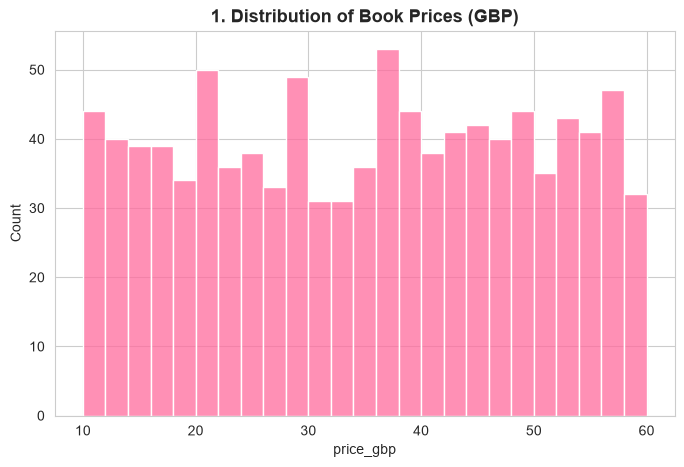

C:\Users\BontleNemalale\AppData\Local\Temp\ipykernel_1268\4111656254.py:16: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(x="rating", y="price_gbp", data=df, ci=None, palette="viridis")
C:\Users\BontleNemalale\AppData\Local\Temp\ipykernel_1268\4111656254.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="rating", y="price_gbp", data=df, ci=None, palette="viridis")


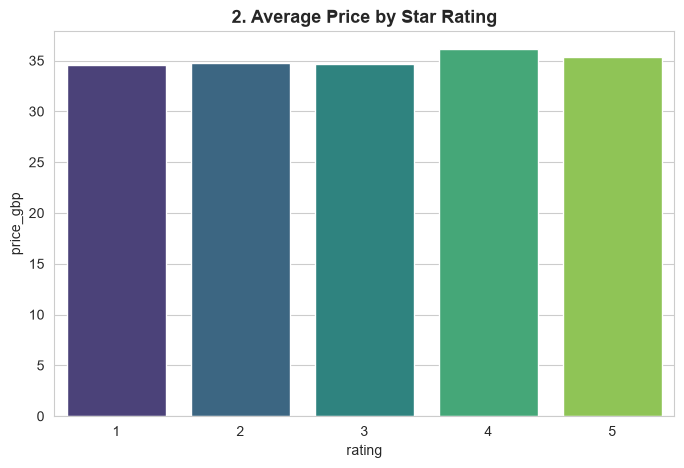

C:\Users\BontleNemalale\AppData\Local\Temp\ipykernel_1268\4111656254.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="price_gbp", y="category", data=df.groupby("category")["price_gbp"].mean().sort_values(ascending=False).head(10).reset_index(), palette="Oranges_r")


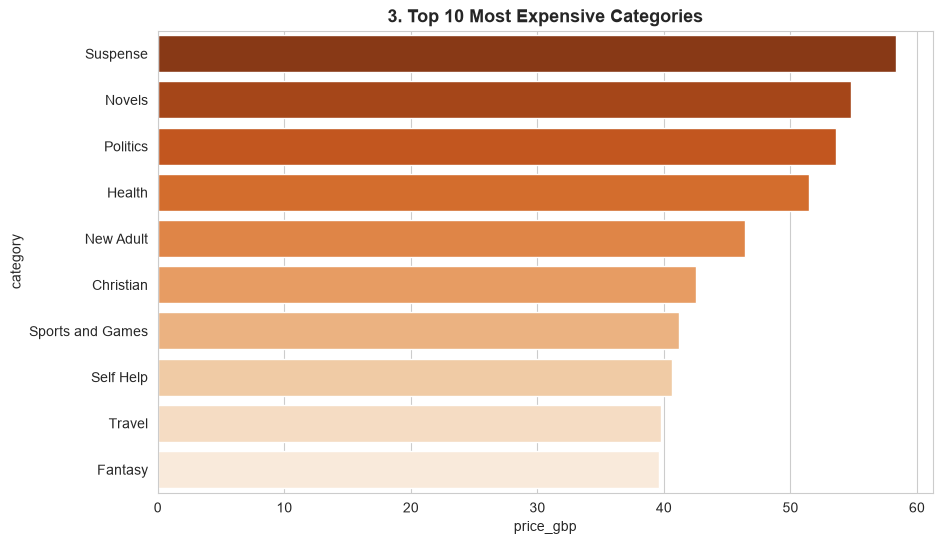

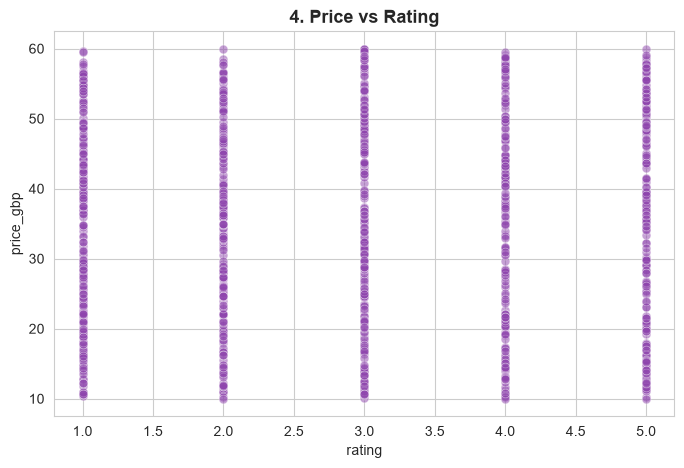

C:\Users\BontleNemalale\AppData\Local\Temp\ipykernel_1268\4111656254.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="rating", y="price_gbp", data=df, palette="Set3")


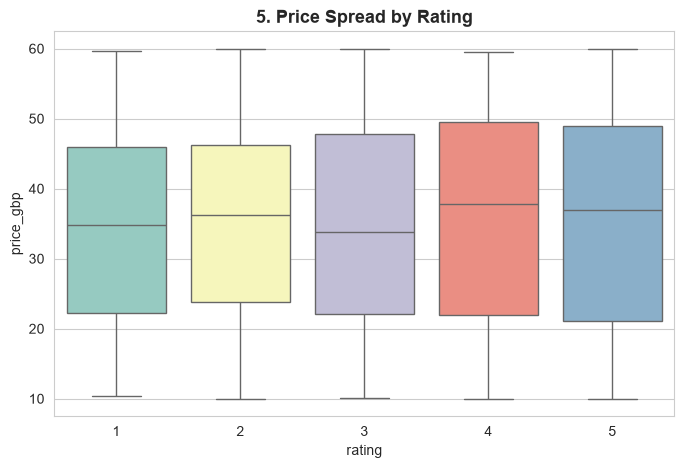

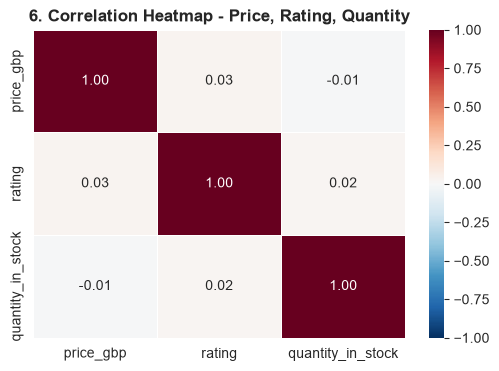

                   price_gbp    rating  quantity_in_stock
price_gbp           1.000000  0.028166          -0.010914
rating              0.028166  1.000000           0.016166
quantity_in_stock  -0.010914  0.016166           1.000000


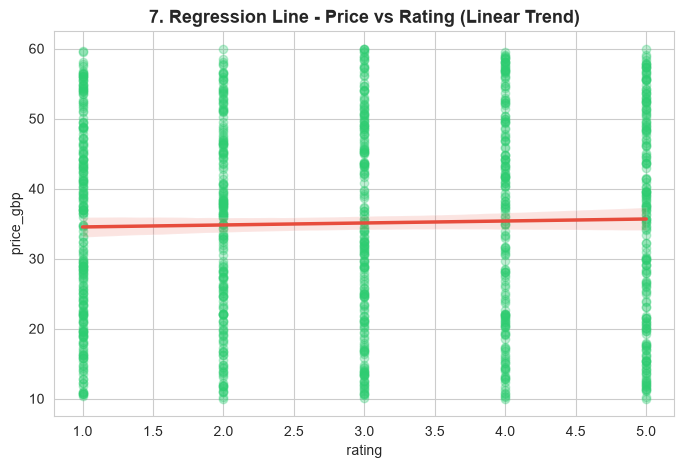

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.facecolor"] = "white"

# 1. Distribution.png
plt.figure(figsize=(8,5))
sns.histplot(df["price_gbp"], bins=25, color="#FF6B9D", edgecolor="white")
plt.title("1. Distribution of Book Prices (GBP)", fontsize=13, fontweight="bold")
plt.show()

# 2. Average price by rating.png
plt.figure(figsize=(8,5))
sns.barplot(x="rating", y="price_gbp", data=df, ci=None, palette="viridis")
plt.title("2. Average Price by Star Rating", fontsize=13, fontweight="bold")
plt.show()

# 3. Top 10 categories.png
plt.figure(figsize=(10,6))
sns.barplot(x="price_gbp", y="category", data=df.groupby("category")["price_gbp"].mean().sort_values(ascending=False).head(10).reset_index(), palette="Oranges_r")
plt.title("3. Top 10 Most Expensive Categories", fontsize=13, fontweight="bold")
plt.show()

# 4. Scatter.png
plt.figure(figsize=(8,5))
sns.scatterplot(x="rating", y="price_gbp", data=df, alpha=0.5, color="#8E44AD", s=40)
plt.title("4. Price vs Rating", fontsize=13, fontweight="bold")
plt.show()

# 5. Boxplot.png
plt.figure(figsize=(8,5))
sns.boxplot(x="rating", y="price_gbp", data=df, palette="Set3")
plt.title("5. Price Spread by Rating", fontsize=13, fontweight="bold")
plt.show()

# 6. CORRELATION HEATMAP.png
plt.figure(figsize=(6,4))
corr = df[["price_gbp","rating","quantity_in_stock"]].corr()
sns.heatmap(corr, annot=True, cmap="RdBu_r", fmt=".2f", vmin=-1, vmax=1, linewidths=0.5)
plt.title("6. Correlation Heatmap - Price, Rating, Quantity", fontsize=12, fontweight="bold")
plt.show()
print(corr)

# 7. REGRESSION LINE.png
plt.figure(figsize=(8,5))
sns.regplot(x="rating", y="price_gbp", data=df, scatter_kws={"alpha":0.3, "color":"#2ECC71"}, line_kws={"color":"#E74C3C", "linewidth":2.5})
plt.title("7. Regression Line - Price vs Rating (Linear Trend)", fontsize=13, fontweight="bold")
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

X = df[["rating","quantity_in_stock","category"]]
y = df["price_gbp"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
pre = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), ["category"])], remainder="passthrough")
model = Pipeline([("pre", pre), ("lr", LinearRegression())])
model.fit(X_train, y_train)
pred = model.predict(X_test)
print("MAE:", round(mean_absolute_error(y_test, pred),2))
print("RMSE:", round(mean_squared_error(y_test, pred, squared=False),2))
print("R2:", round(r2_score(y_test, pred),3))

In [6]:
import matplotlib.pyplot as plt
plt.figure(figsize=(7,5))
plt.scatter(y_test, pred, alpha=0.4)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="red", linestyle="--")
plt.xlabel("Actual Price (GBP)")
plt.ylabel("Predicted Price (GBP)")
plt.title("Predicted vs Actual Price - Linear Regression")
plt.show()

NameError: name 'y_test' is not defined

<Figure size 700x500 with 0 Axes>

In [9]:
import matplotlib.pyplot as plt
plt.figure(figsize=(7,5))
plt.scatter(y_test, pred, alpha=0.5, color="#3498DB", s=30)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="#E74C3C", linestyle="--", linewidth=2)
plt.xlabel("Actual Price (GBP)")
plt.ylabel("Predicted Price (GBP)")
plt.title("Predicted vs Actual Price - Linear Regression", fontweight="bold")
plt.show()

NameError: name 'y_test' is not defined

<Figure size 700x500 with 0 Axes>